# CLFG WY2026 SNOWPACK comparison with TopoPyScale forcing

Six snow-free October starts use the nearest available CLFG grid cell from the 20, 50, 100, 250, 500, and 1,000 m TopoPyScale runs. The runs share the original CLFG SNOWPACK configuration, site elevation, flat snow column, and 1.2 °C rain–snow threshold. The input radiation already includes the downscaler's terrain treatment. Temperatures enter SNOWPACK directly from each forcing cell. The input metadata records cell elevation and the number of hours where the downscaler used its surface-only fallback.

The four existing HRRR-AK cases end on September 29 at 04:00 UTC, 43 hours before the TopoPyScale runs. Seasonal peaks use the shared period. The seasonal plots show the available coverage for each run. The May 25 field record is approximately 2 m of snow and has no measurement time, so the comparison uses the range and mean across that local day.

In [1]:
from pathlib import Path
import json
import os
import sys

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

cwd = Path.cwd()
candidates = (cwd, *cwd.parents, cwd / "jif_snow_modeling")
root = next(p for p in candidates if (p / "sites/clfg/site_info.txt").is_file())
sys.path.insert(0, str(root / "sites/radar_sites/scripts"))
from prepare_radar_site_forcing import MODEL_ROOT, read_smet
from visualization import OBSERVATION_COLOR, RC_PARAMS

plt.rcParams.update(RC_PARAMS)
info = dict(line.split(": ", 1) for line in (root / "sites/clfg/site_info.txt").read_text().splitlines())
observed = float(info["Snow depth"].split()[1])
timezone = "America/Juneau"
day = pd.Timestamp(info["Observation date"], tz=timezone)
next_day = day + pd.Timedelta(days=1)
site_dir = Path(os.environ.get("CLFG_MODEL_SITE", MODEL_ROOT / "clfg")).expanduser()
sensitivity = Path(os.environ.get("CLFG_SENSITIVITY_SITE", site_dir)).expanduser()
expected = pd.date_range("2025-10-01", periods=8760, freq="h")
reference_meta = json.loads((site_dir / "input/hrrrak_WY2026/hrrrak_clfg_WY2026.json").read_text())
reference_hours = pd.date_range(reference_meta["start_UTC"], reference_meta["end_UTC"], freq="h")
common_end = reference_hours[-1].tz_localize("UTC").tz_convert(timezone)
resolutions = (20, 50, 100, 250, 500, 1000)
baseline = {
    "hrrrak":"Raw HRRR-AK", "hrrrak_lapserate":"HRRR-AK, 0.60 °C/100 m",
    "hrrrak_lapserate_0p5":"HRRR-AK, 0.50 °C/100 m",
    "hrrrak_lapserate_0p47":"HRRR-AK, 0.47 °C/100 m",
}
topo = {f"topopyscale_{m}m":f"TopoPyScale {m:,} m" for m in resolutions}
labels = {**baseline, **topo}
colors = dict(zip(labels, ["#4e4e4e","#503692","#cf6f15","#168259",
                             *plt.cm.viridis(np.linspace(.12,.87,len(topo)))]))
models = {}
diagnostics = []
for case, label in labels.items():
    parent = sensitivity if case in ("hrrrak_lapserate_0p5", "hrrrak_lapserate_0p47") else site_dir
    station = f"{case}_clfg_WY2026"
    header, df = read_smet(parent / "output" / f"{station}_heatflux_soiltemp_zero.smet",
                           ["timestamp", "HS_mod", "SWE"])
    units = dict(zip(header["fields"].split(), map(float,header["units_multiplier"].split())))
    if (units["HS_mod"],units["SWE"]) != (.01,1.0):
        raise ValueError(f"Unexpected SNOWPACK units for {station}")
    valid_hours = expected if case in topo else reference_hours
    if not df.index.equals(valid_hours) or not np.isfinite(df).all().all():
        raise ValueError(f"Incomplete WY2026 output for {station}")
    df.index = df.index.tz_localize("UTC").tz_convert(timezone)
    models[case] = df.assign(depth_m=df.HS_mod*.01, swe_mm=df.SWE)
    if case in topo:
        stem = parent / "input" / f"{case}_WY2026" / station
        meta = json.loads(stem.with_suffix(".json").read_text())
        _, forcing = read_smet(stem.with_suffix(".smet"), ["timestamp","TA","PSUM"])
        if not forcing.index.equals(expected):
            raise ValueError(f"Incomplete forcing for {station}")
        diagnostics.append(dict(
            run=label, grid_elevation_m=meta["forcing_elevation_m"],
            cell_minus_site_m=meta["cell_minus_site_m"], fallback_hours=meta["profile_fallback_hours"],
            mean_air_temperature_C=forcing.TA.mean()-273.15, total_precip_mm=forcing.PSUM.sum()))
print(f"{len(topo)} TopoPyScale runs × {len(expected):,} hours. "
      f"{len(baseline)} HRRR-AK runs × {len(reference_hours):,} hours.")


6 TopoPyScale runs × 8,760 hours. 4 HRRR-AK runs × 8,717 hours.


## Seasonal snow depth

The combined figure shows the TopoPyScale run whose mean snow depth on May 25 (Juneau local time) is closest to the field observation.

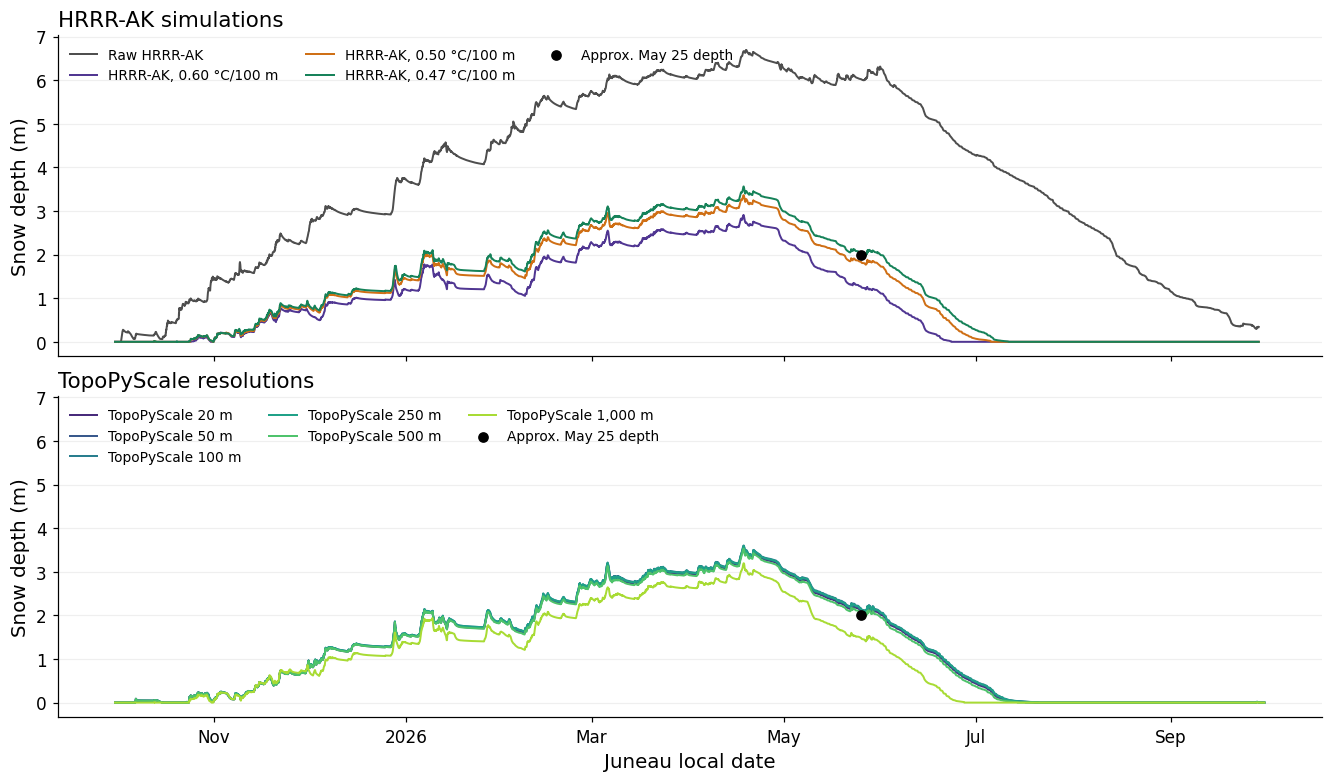

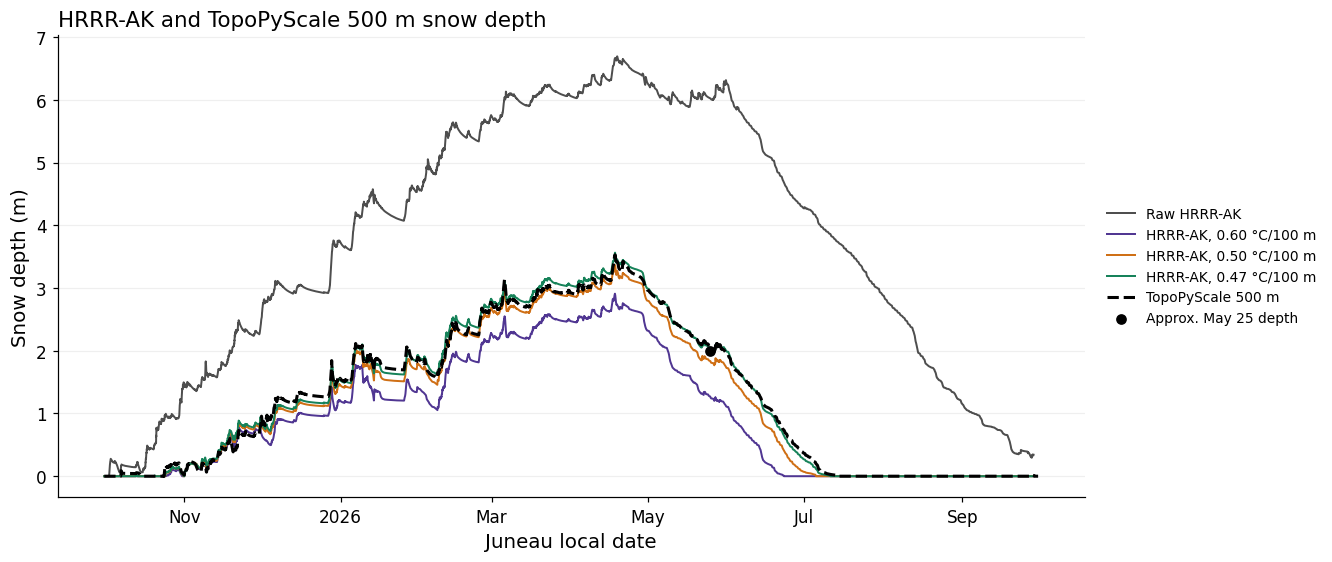

In [2]:
may25_depth = {}
for case, frame in models.items():
    depth = frame.loc[(frame.index >= day) & (frame.index < next_day), "depth_m"]
    if len(depth) != 24:
        raise ValueError(f"Expected 24 May 25 hours for {case}")
    may25_depth[case] = depth


def plot_snow_depth(ax, cases, comparison_case=None):
    for case, label in cases.items():
        frame = models[case]
        is_comparison = case == comparison_case
        ax.plot(frame.index, frame.depth_m, color="black" if is_comparison else colors[case],
                label=label, linestyle="--" if is_comparison else "-",
                linewidth=2 if is_comparison else 1.3)
    ax.scatter(day + pd.Timedelta(hours=12), observed, color=OBSERVATION_COLOR,
               label="Approx. May 25 depth", zorder=4)
    ax.set_ylabel("Snow depth (m)")
    ax.grid(axis="y", alpha=.20)


def format_seasonal_dates(ax):
    locator = mdates.AutoDateLocator(tz=timezone)
    ax.xaxis.set_major_locator(locator)
    ax.xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator, tz=timezone))
    ax.set_xlabel("Juneau local date")


fig, (ax_hrrr, ax_topo) = plt.subplots(
    2, 1, figsize=(12, 7), sharex=True, sharey=True, layout="constrained"
)
plot_snow_depth(ax_hrrr, baseline)
plot_snow_depth(ax_topo, topo)
ax_hrrr.set_title("HRRR-AK simulations", loc="left")
ax_topo.set_title("TopoPyScale resolutions", loc="left")
for ax in (ax_hrrr, ax_topo):
    ax.legend(loc="upper left", frameon=False, ncol=3, fontsize=9)
format_seasonal_dates(ax_topo)
plt.show()


best_topo = min(topo, key=lambda case: abs(may25_depth[case].mean() - observed))
fig, ax = plt.subplots(figsize=(12, 5), layout="constrained")
plot_snow_depth(ax, {**baseline, best_topo: topo[best_topo]}, comparison_case=best_topo)
ax.set_title(f"HRRR-AK and {topo[best_topo]} snow depth", loc="left")
format_seasonal_dates(ax)
ax.legend(loc="center left", bbox_to_anchor=(1.01, .5), frameon=False, fontsize=9)
plt.show()

## May 25 depth and seasonal peaks

,Mean depth May 25 (m),Min depth May 25 (m),Max depth May 25 (m),Mean minus field depth (m),Peak depth (m),Peak SWE (mm w.e.),Peak SWE date
Run,,,,,,,
Raw HRRR-AK,6.02,6.00,6.03,4.02,6.69,3269.80,2026-05-31
"HRRR-AK, 0.60 °C/100 m",1.26,1.24,1.28,-0.74,2.91,1329.09,2026-04-21
"HRRR-AK, 0.50 °C/100 m",1.83,1.81,1.84,-0.17,3.37,1554.09,2026-04-28
"HRRR-AK, 0.47 °C/100 m",2.04,2.02,2.06,0.04,3.56,1636.47,2026-04-29
TopoPyScale 20 m,2.10,2.07,2.13,0.10,3.57,1615.93,2026-04-28
TopoPyScale 50 m,2.13,2.10,2.16,0.13,3.59,1626.81,2026-04-29
TopoPyScale 100 m,2.16,2.13,2.19,0.16,3.60,1637.83,2026-04-29
TopoPyScale 250 m,2.15,2.11,2.18,0.15,3.59,1634.93,2026-04-28
TopoPyScale 500 m,2.04,2.01,2.07,0.04,3.53,1602.85,2026-04-21


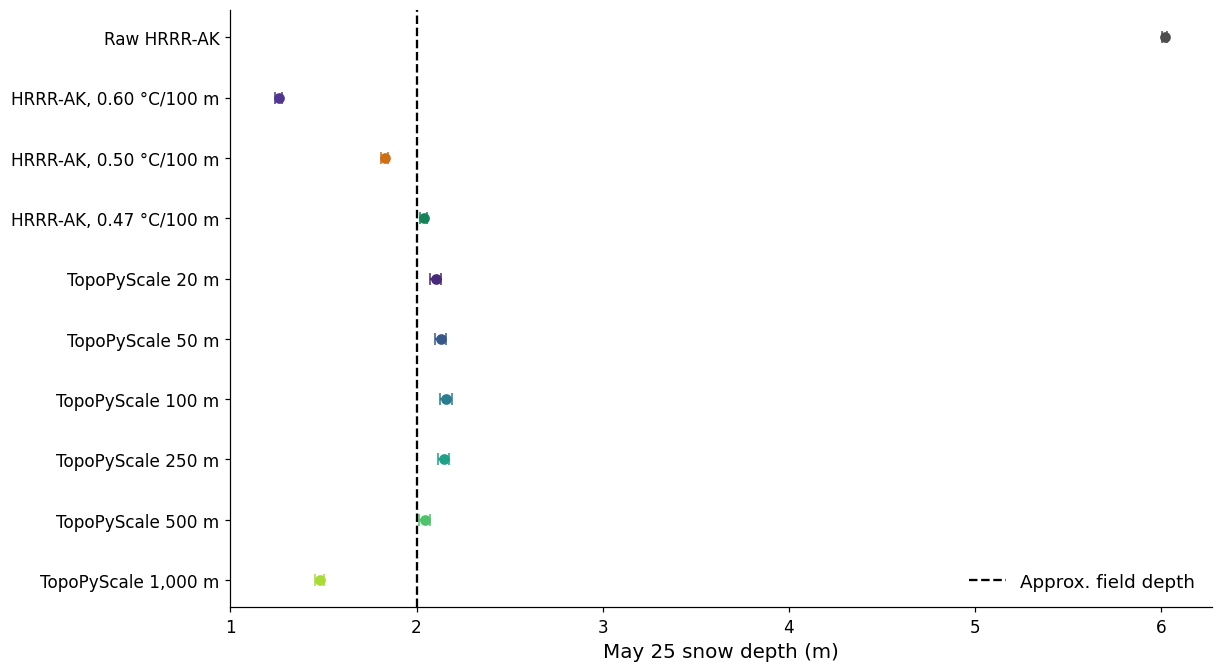

In [3]:
rows = []
for case, frame in models.items():
    depth = may25_depth[case]
    common = frame.loc[:common_end]
    rows.append({"Run":labels[case],"Mean depth May 25 (m)":depth.mean(),
                 "Min depth May 25 (m)":depth.min(),"Max depth May 25 (m)":depth.max(),
                 "Mean minus field depth (m)":depth.mean()-observed,
                 "Peak depth (m)":common.depth_m.max(),"Peak SWE (mm w.e.)":common.swe_mm.max(),
                 "Peak SWE date":common.swe_mm.idxmax().date()})
metrics = pd.DataFrame(rows).set_index("Run")
fig, ax = plt.subplots(figsize=(11,6),layout="constrained")
for i,(case,row) in enumerate(zip(labels,metrics.itertuples(index=False,name=None))):
    mean, low, high = row[:3]
    ax.errorbar(mean,i,xerr=[[mean-low],[high-mean]],fmt="o",capsize=4,color=colors[case])
ax.axvline(observed,color=OBSERVATION_COLOR,linestyle="--",label="Approx. field depth")
ax.set(yticks=np.arange(len(labels)),yticklabels=metrics.index,xlabel="May 25 snow depth (m)")
ax.invert_yaxis()
ax.legend(frameon=False)
plt.show()
display(metrics.round(2))


## TopoPyScale forcing cells

In [4]:
display(pd.DataFrame(diagnostics).set_index("run").round(2))

,grid_elevation_m,cell_minus_site_m,fallback_hours,mean_air_temperature_C,total_precip_mm
run,,,,,
TopoPyScale 20 m,652.40,0.38,0,1.25,4693.34
TopoPyScale 50 m,651.41,-0.61,0,1.24,4693.34
TopoPyScale 100 m,649.98,-2.04,0,1.22,4693.34
TopoPyScale 250 m,650.06,-1.97,0,1.22,4693.34
TopoPyScale 500 m,652.98,0.96,0,1.27,4693.34
"TopoPyScale 1,000 m",711.36,59.34,0,1.75,4814.79


## Absolute snow-depth error on May 25

With one field observation, each run’s mean absolute error (MAE) is the absolute difference between its May 25 daily mean snow depth and the observed depth.

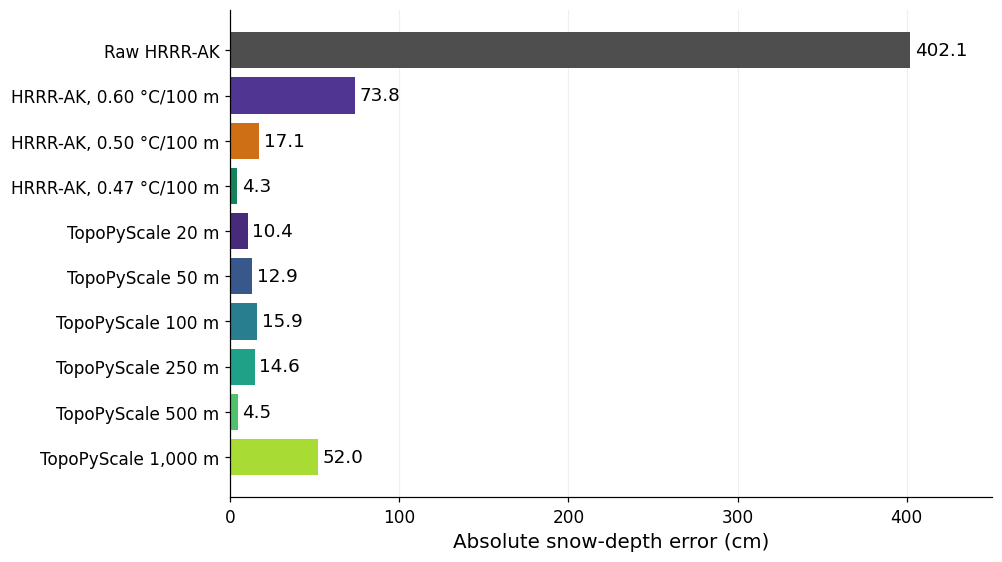

In [5]:
absolute_errors_cm = metrics["Mean minus field depth (m)"].abs() * 100

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
bars = ax.barh(absolute_errors_cm.index, absolute_errors_cm,
               color=[colors[case] for case in labels])
ax.bar_label(bars, fmt="%.1f", padding=3)
ax.invert_yaxis()
ax.set(xlabel="Absolute snow-depth error (cm)", xlim=(0, absolute_errors_cm.max() * 1.12))
ax.grid(axis="x", alpha=.2)
ax.set_axisbelow(True)
plt.show()